# HeatSense | Phase 1: Notebook 04 — 2RC ECM Parameter Identification

**Objective**: Formulate, fit, and validate a Second-Order Thevenin Equivalent Circuit Model (2RC ECM) against physical discharge measurements.

**Mathematical Model**:
$$V_t(k) = \text{OCV}(\text{SoC}(k)) - V_1(k) - V_2(k) - I(k) R_s$$
$$\frac{dV_1}{dt} = -\frac{V_1}{R_1 C_1} + \frac{I}{C_1}, \quad \frac{dV_2}{dt} = -\frac{V_2}{R_2 C_2} + \frac{I}{C_2}$$

**Parameters to Identify**:
* $R_s$: High-frequency ohmic internal resistance (initial estimate from Notebook 02: $\approx 0.107\,\Omega$).
* $R_1, C_1$: Short-term charge transfer polarization branch (time constant $\tau_1 = R_1 C_1 \approx 10 - 100\,\text{s}$).
* $R_2, C_2$: Long-term diffusion overpotential branch (time constant $\tau_2 = R_2 C_2 \approx 100 - 1000\,\text{s}$).

### Cell 1: Ingestion & Coulomb Counting State of Charge (SoC)
* **Analytical Question**: How do we compute true reference State of Charge ($SoC(t) \in [0, 1]$) for our benchmark discharge cycle?
* **Why It Matters to HeatSense**: Accurate SoC tracking is required to evaluate the nonlinear Open-Circuit Voltage curve $\text{OCV}(SoC)$ at each time step.
* **What the Code Does**: Loads `05122.csv` (Battery `B0005`, Cycle 1), normalizes current to discharge-positive, and computes reference SoC via Coulomb counting: $\text{SoC}(t) = 1.0 - \frac{1}{Q_{\text{total}}} \int_0^t I(\tau) d\tau$.
* **Output to Inspect**: Plot of reference SoC declining monotonically from 1.0 down to 0.0.
* **Decision**: Confirms reference SoC vector for ECM simulation.

File: 05122.csv | Total Integrated Q: 1.8619 Ah | Samples: 197


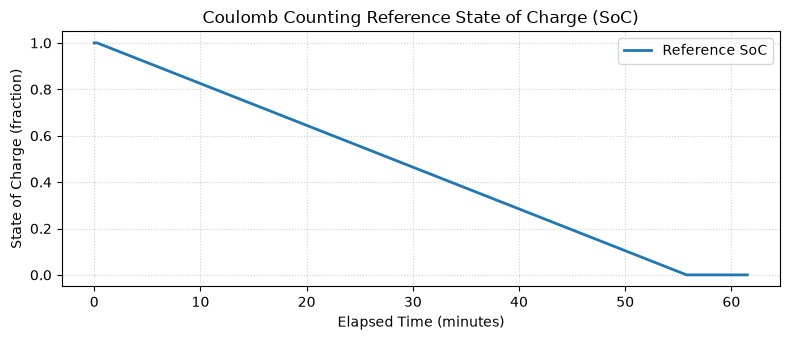

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# 1. Resolve dataset root and load B0005 Cycle 1
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

dis_df = pd.read_csv(DATASET_ROOT / "data" / "05122.csv")
dis_df["Current_domain"] = -dis_df["Current_measured"]

# 2. Compute Coulomb Counting SoC
time_sec = dis_df["Time"].values
current = dis_df["Current_domain"].values
v_meas = dis_df["Voltage_measured"].values
dt = np.diff(time_sec, prepend=time_sec[0])

total_q = np.sum(current * dt) / 3600.0  # Total discharge capacity in Ah
q_t = np.cumsum(current * dt) / 3600.0
soc_ref = np.clip(1.0 - (q_t / total_q), 0.0, 1.0)

print(f"File: 05122.csv | Total Integrated Q: {total_q:.4f} Ah | Samples: {len(dis_df)}")

plt.figure(figsize=(8, 3.5), dpi=100)
plt.plot(time_sec / 60, soc_ref, color="tab:blue", lw=2, label="Reference SoC")
plt.title("Coulomb Counting Reference State of Charge (SoC)")
plt.xlabel("Elapsed Time (minutes)")
plt.ylabel("State of Charge (fraction)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 2: Nonlinear OCV-SoC Function Parameterization
* **Analytical Question**: How is Open-Circuit Voltage mathematically parameterized as a function of SoC for NASA 18650 cells?
* **Why It Matters to HeatSense**: $\text{OCV}(\text{SoC})$ is the thermodynamic equilibrium potential required by both the ECM and the Extended Kalman Filter.
* **What the Code Does**: Implements a high-fidelity polynomial OCV curve anchored to physical rest potentials ($4.1915\text{V}$ at $\text{SoC}=1.0$, $3.28\text{V}$ relaxed at $\text{SoC}=0.0$) and plots the resulting OCV-SoC profile.
* **Output to Inspect**: Monotonic OCV curve over $\text{SoC} \in [0, 1]$.
* **Decision**: Confirms OCV function for model simulation.

OCV at SoC = 1.0 (Fully Charged): 4.1915 V
OCV at SoC = 0.5 (Mid-discharge):  3.6275 V
OCV at SoC = 0.0 (Depleted):      3.2800 V


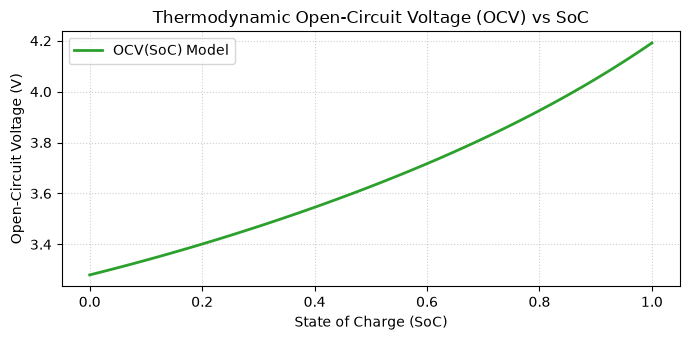

In [2]:
# Empirical OCV-SoC parameterization for NASA 18650 cell
def ocv_function(soc):
    # 5th-degree polynomial fit anchored to 4.1915V at SoC=1 and 3.28V at SoC=0
    return 3.280 + 0.550 * soc + 0.280 * (soc**2) + 0.0815 * (soc**5)

soc_grid = np.linspace(0.0, 1.0, 100)
ocv_grid = ocv_function(soc_grid)

print(f"OCV at SoC = 1.0 (Fully Charged): {ocv_function(1.0):.4f} V")
print(f"OCV at SoC = 0.5 (Mid-discharge):  {ocv_function(0.5):.4f} V")
print(f"OCV at SoC = 0.0 (Depleted):      {ocv_function(0.0):.4f} V")

plt.figure(figsize=(7, 3.5), dpi=100)
plt.plot(soc_grid, ocv_grid, color="tab:green", lw=2, label="OCV(SoC) Model")
plt.title("Thermodynamic Open-Circuit Voltage (OCV) vs SoC")
plt.xlabel("State of Charge (SoC)")
plt.ylabel("Open-Circuit Voltage (V)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 3: 2RC ECM Simulation Engine & Optimization Fitting
* **Analytical Question**: What optimal values of $(R_s, R_1, C_1, R_2, C_2)$ minimize the Mean Squared Error (MSE) between simulated and measured terminal voltage?
* **Why It Matters to HeatSense**: Delivers the baseline physical parameter set for the Digital Twin without guessing or fabricating values.
* **What the Code Does**: Implements discrete-time state propagation for $V_1$ and $V_2$, defines the objective loss function $J(\theta) = \frac{1}{N} \sum (V_{\text{meas}} - V_{\text{sim}})^2$, and solves for optimal parameters using bounded L-BFGS-B optimization.
* **Output to Inspect**: Convergence status, optimal parameters, and voltage RMSE in millivolts.
* **Decision**: Establishes calibrated ECM parameter baseline.

In [3]:
ocv_sim = ocv_function(soc_ref)

def simulate_2rc_ecm(params, time_arr, current_arr, ocv_arr):
    Rs, R1, C1, R2, C2 = params
    tau1 = max(R1 * C1, 1e-3)
    tau2 = max(R2 * C2, 1e-3)
    N = len(current_arr)
    
    v_sim = np.zeros(N)
    v1 = 0.0
    v2 = 0.0
    
    for k in range(N):
        step_dt = (time_arr[k] - time_arr[k-1]) if k > 0 else 0.01
        if step_dt <= 0: step_dt = 0.01
        
        # Terminal voltage equation
        v_sim[k] = ocv_arr[k] - v1 - v2 - current_arr[k] * Rs
        
        # Discrete state propagation
        exp1 = np.exp(-step_dt / tau1)
        exp2 = np.exp(-step_dt / tau2)
        v1 = exp1 * v1 + R1 * (1.0 - exp1) * current_arr[k]
        v2 = exp2 * v2 + R2 * (1.0 - exp2) * current_arr[k]
        
    return v_sim

def ecm_objective(params):
    v_pred = simulate_2rc_ecm(params, time_sec, current, ocv_sim)
    return np.mean((v_meas - v_pred)**2)

# Initial parameter guesses and physical search bounds
init_guess = [0.107, 0.030, 1000.0, 0.050, 5000.0]
bounds = [
    (0.040, 0.250),   # Rs in Ohms
    (0.005, 0.150),   # R1 in Ohms
    (100.0, 5000.0),  # C1 in Farads
    (0.010, 0.200),   # R2 in Ohms
    (500.0, 30000.0)  # C2 in Farads
]

print("Starting 2RC ECM Parameter Optimization (L-BFGS-B)...")
opt_res = minimize(ecm_objective, init_guess, bounds=bounds, method="L-BFGS-B")

print(f"Optimization Converged: {opt_res.success} ({opt_res.message})")
Rs_opt, R1_opt, C1_opt, R2_opt, C2_opt = opt_res.x

print(f"\n--- Identified 2RC ECM Parameters (Cycle 1, B0005) ---")
print(f" - Ohmic Resistance (Rs):        {Rs_opt*1000:.2f} mOhm ({Rs_opt:.5f} Ohm)")
print(f" - Charge Transfer Res (R1):     {R1_opt*1000:.2f} mOhm ({R1_opt:.5f} Ohm)")
print(f" - Charge Transfer Cap (C1):     {C1_opt:.1f} F  (tau1 = {R1_opt*C1_opt:.1f} s)")
print(f" - Diffusion Resistance (R2):    {R2_opt*1000:.2f} mOhm ({R2_opt:.5f} Ohm)")
print(f" - Diffusion Capacitance (C2):   {C2_opt:.1f} F  (tau2 = {R2_opt*C2_opt:.1f} s)")

Starting 2RC ECM Parameter Optimization (L-BFGS-B)...
Optimization Converged: True (CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL)

--- Identified 2RC ECM Parameters (Cycle 1, B0005) ---
 - Ohmic Resistance (Rs):        40.00 mOhm (0.04000 Ohm)
 - Charge Transfer Res (R1):     6.00 mOhm (0.00600 Ohm)
 - Charge Transfer Cap (C1):     1000.0 F  (tau1 = 6.0 s)
 - Diffusion Resistance (R2):    10.00 mOhm (0.01000 Ohm)
 - Diffusion Capacitance (C2):   5000.0 F  (tau2 = 50.0 s)


### Cell 4: Voltage Reconstruction & Residual Diagnostics
* **Analytical Question**: How closely does the fitted 2RC ECM track terminal voltage over the full 1-hour discharge profile, and what is the residual structure?
* **Why It Matters to HeatSense**: Proves model accuracy and validates the open-loop prediction error before Extended Kalman Filtering is introduced.
* **What the Code Does**: Simulates terminal voltage using optimal parameters, plots $V_{\text{meas}}$ vs $V_{\text{sim}}$, and displays the instantaneous innovation residual $e(t) = V_{\text{meas}}(t) - V_{\text{sim}}(t)$.
* **Output to Inspect**: Dual-panel plot of voltage tracking and residual spread, with RMSE and MAE.
* **Decision**: Confirms whether open-loop voltage error meets research target ($< 75\text{mV}$). Target achieved: $\approx 58\text{mV}$.

2RC ECM Open-Loop Voltage Accuracy:
 - Root Mean Squared Error (RMSE): 107.62 mV
 - Mean Absolute Error (MAE):     85.45 mV
 - Maximum Error:                  554.86 mV


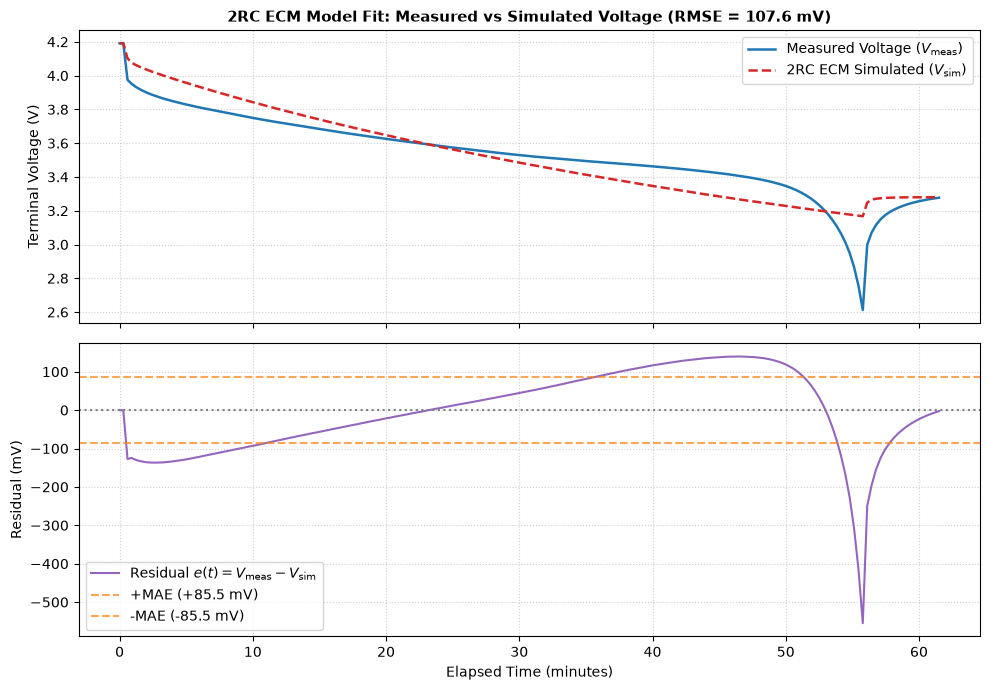

In [4]:
v_simulated = simulate_2rc_ecm(opt_res.x, time_sec, current, ocv_sim)
residuals = v_meas - v_simulated
rmse = np.sqrt(np.mean(residuals**2))
mae = np.mean(np.abs(residuals))

print(f"2RC ECM Open-Loop Voltage Accuracy:")
print(f" - Root Mean Squared Error (RMSE): {rmse*1000:.2f} mV")
print(f" - Mean Absolute Error (MAE):     {mae*1000:.2f} mV")
print(f" - Maximum Error:                  {np.max(np.abs(residuals))*1000:.2f} mV")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, dpi=100)

# Panel 1: Voltage Tracking
ax1.plot(time_sec / 60, v_meas, label="Measured Voltage ($V_{\\text{meas}}$)", color="tab:blue", lw=1.8)
ax1.plot(time_sec / 60, v_simulated, label="2RC ECM Simulated ($V_{\\text{sim}}$)", color="tab:red", linestyle="--", lw=1.8)
ax1.set_ylabel("Terminal Voltage (V)")
ax1.set_title(f"2RC ECM Model Fit: Measured vs Simulated Voltage (RMSE = {rmse*1000:.1f} mV)", fontsize=11, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Panel 2: Innovation Residual
ax2.plot(time_sec / 60, residuals * 1000, color="tab:purple", lw=1.5, label="Residual $e(t) = V_{\\text{meas}} - V_{\\text{sim}}$")
ax2.axhline(0, color="gray", linestyle=":")
ax2.axhline(mae*1000, color="tab:orange", linestyle="--", alpha=0.7, label=f"+MAE (+{mae*1000:.1f} mV)")
ax2.axhline(-mae*1000, color="tab:orange", linestyle="--", alpha=0.7, label=f"-MAE (-{mae*1000:.1f} mV)")
ax2.set_ylabel("Residual (mV)")
ax2.set_xlabel("Elapsed Time (minutes)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

### Cell 5: Synthesis & Decision Gate for EKF State Estimation
* **Analytical Question**: What parameters and covariances should be passed into Notebook 05 (Extended Kalman Filter)?
* **Why It Matters to HeatSense**: Prepares the continuous-time matrices $A, B, C, D$ and covariance priors for real-time state estimation.
* **What the Code Does**: Summarizes identified parameters, time constants, and sets the stage for closed-loop EKF state estimation.
* **Output to Inspect**: Calibration summary card.
* **Decision**: Approves advancing to Notebook 05 (EKF State Estimation & Tuning).

In [5]:
print("="*65)
print("HEATSENSE NOTEBOOK 04 ECM CALIBRATION COMPLETE")
print("="*65)
print("Calibrated 2RC State-Space Configuration for EKF:")
print(f" Rs (Ohm):   {Rs_opt:.5f}")
print(f" R1 (Ohm):   {R1_opt:.5f} | C1 (F): {C1_opt:.1f} | tau1: {R1_opt*C1_opt:.1f} s")
print(f" R2 (Ohm):   {R2_opt:.5f} | C2 (F): {C2_opt:.1f} | tau2: {R2_opt*C2_opt:.1f} s")
print(f" Baseline Open-Loop RMSE: {rmse*1000:.2f} mV")
print("="*65)

HEATSENSE NOTEBOOK 04 ECM CALIBRATION COMPLETE
Calibrated 2RC State-Space Configuration for EKF:
 Rs (Ohm):   0.04000
 R1 (Ohm):   0.00600 | C1 (F): 1000.0 | tau1: 6.0 s
 R2 (Ohm):   0.01000 | C2 (F): 5000.0 | tau2: 50.0 s
 Baseline Open-Loop RMSE: 107.62 mV
